# Learning the Kirchhoff–Carrier string, one calculation at a time

We will follow **Riccardo Russo's string simulation in PyTorch**, learning the physics and calculus as we need them.
You only need basic algebra and Python. You do not need to understand derivatives, integrals, or matrices already.

This is a **standalone implementation**: every parameter and function used by the simulator is defined here.
There is no import from `src/kc_string.py`, no generated module, and no SymPy. Equations are ordinary Markdown LaTeX.
The separate Python module is maintained independently for now.

For each topic: **what physical question are we asking → what do the symbols mean → a small example → the code**.
Sections labelled **Deeper derivation** preserve the paper-level equations; read them after the introductory explanation.
The little teaching examples use separate variables and do not change the reference settings.

### Reading map
1. [What is a simulated sound?](#1.-What-is-a-simulated-sound?)
2. [What is the string made of?](#2.-What-is-the-string-made-of?)
3. [Position, velocity, acceleration: meeting calculus](#3.-Position,-velocity,-acceleration:-meeting-calculus)
4. [Why does the string move back?](#4.-Why-does-the-string-move-back?)
5. [Waves and damping](#5.-Waves-and-damping)
6. [Replacing a continuous string with a grid](#6.-Replacing-a-continuous-string-with-a-grid)
7. [Moving from one state to the next](#7.-Moving-from-one-state-to-the-next)
8. [Run the notebook's simulator and compare with Russo](#8.-Run-the-notebook's-simulator-and-compare-with-Russo)

**Run:** select the project's Pixi Python environment, restart the kernel, and Run All. The short demonstration
and Octave comparison keep routine execution practical. `pixi run notebook-check` does the same in a fresh kernel.
The simulation defaults remain `SAV=False`, damping on, a first-mode initial shape, oversampling 512, and duration 0.06 s.

**Sources.** [Russo, Ducceschi & Bilbao (2026)](https://doi.org/10.1007/s11071-026-12708-0), especially equations
(50), (71), and (73), and the pinned
[MATLAB reference](https://github.com/Nemus-Project/nLinStringsConv-SAV/blob/5253d5c8dc7e2645c925fd45f57f6bc32b66f2ec/KCstring/KCStringSAV_noSplit.m).
Supporting reading: Stefan Bilbao, *Numerical Sound Synthesis* (Wiley, 2009), chapters 2, 5–8;
§7.3 for damping and §8.1 for Kirchhoff–Carrier motion. Book page numbers below are **printed page numbers**.
These explanations and illustrations are written for this notebook; the book is not bundled with the repository.

SAV means **scalar auxiliary variable**, an alternative numerical formulation studied in the paper.
We follow its non-SAV benchmark branch; no auxiliary variable is needed in this notebook.


### Our tools
`math` handles ordinary scalar arithmetic. A PyTorch **tensor** is an array of numbers: later, one entry will
hold the displacement of one string point. We use 64-bit floating-point tensors to compare closely with MATLAB.
Matplotlib draws the teaching figures. Importing a tool does not yet simulate anything.

In [1]:
import math
from pathlib import Path
import shutil
import subprocess
import tempfile

import torch
import matplotlib.pyplot as plt

# The reference test needs the submodule; the simulator itself does not.
project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "nLinStringsConv-SAV" / "KCstring" / "KCStringSAV_noSplit.m").is_file()),
    None,
)

## 1. What is a simulated sound?

Imagine marking a point halfway along a string. Record how far it moves up or down as time passes.
Those measurements make a waveform. A **snapshot** shows many points at one instant; a **waveform** follows
one point through many instants. They have different horizontal axes: position versus time.

We write $u(x,t)$ for displacement: “the height of the string at position $x$, at time $t$”.
For example, $u(0.5,0)=0.002$ means the midpoint of a one-metre string starts two millimetres above rest.
Negative displacement means below rest, not a negative amount of string.

A computer takes discrete steps. If the sample rate is $f_s=44100$ samples/s, each step lasts
$$\Delta t=\frac{1}{f_s}=\frac{1}{44100}\ \mathrm{s}\approx22.68\ \mathrm{microseconds}.$$
The reciprocal appears because 44,100 equal time intervals must fit into one second.
For duration $T$, the approximate number of intervals is $Tf_s$.
**Oversampling** multiplies the working sample rate: it gives the numerical method smaller time steps.
It does not automatically improve the physical model.

The output here is displacement in metres, not a microphone pressure recording. Turning it into a listenable audio file
would also require suitable resampling and amplitude scaling; we compare the raw displacement samples instead.

In [2]:
# Reference simulation settings. Restart and Run All after editing these.
SAV = False
damp_on = True
base_sample_rate = 44_100
oversampling_factor = 512
duration_seconds = 0.06
amplitude = 2e-3  # 2 × 10^-3 m = 2 mm

print(f"Base interval: {1 / base_sample_rate * 1e6:.3f} microseconds")
print(f"Requested working rate: {base_sample_rate * oversampling_factor:,} samples/s")
# Later we slightly adjust the working interval to fit the spatial grid.

Base interval: 22.676 microseconds
Requested working rate: 22,579,200 samples/s


## 2. What is the string made of?

### From radius to mass: follow the units
Cut the string across its width. The cut face is a circle with radius $r$ (half the diameter), so its area is
$$A=\pi r^2.$$
Squaring a length gives an area: metres × metres = square metres. Here $\pi\approx3.14159$ is the circle constant.
Doubling the radius makes the area **four** times larger.

A straight cylinder of length $L$ has volume $AL$. **Density** $\rho$ tells us how many kilograms occupy each
cubic metre. Therefore
$$\text{mass}=\rho\times\text{volume}=\rho AL.$$
Dividing by length gives **linear mass density**, or mass per metre:
$$\mu=\frac{\rho AL}{L}=\rho A,\qquad
[\mu]=\frac{\mathrm{kg}}{\mathrm{m}^3}\,\mathrm{m}^2=\frac{\mathrm{kg}}{\mathrm m}.$$
This is Russo's `rA`. A short segment of length $\Delta x$ has mass $\mu\Delta x$.
Checking units is a useful way to detect a missing factor.

In [3]:
# String parameters, matching the MATLAB reference.
material_density = 8.05 * 10**3  # rho, kg/m^3
tension = 75                    # T0, N
radius = 3.5560e-4               # r, m
young_modulus = 174e9            # E, Pa = N/m^2
length = 1                      # L, m

area = math.pi * radius**2
linear_mass_density = material_density * area

print(f"Cross-sectional area: {area:.8g} m²")
print(f"Mass of the entire string: {linear_mass_density * length * 1000:.5f} g")
print(f"Mass of a 1 cm segment: {linear_mass_density * 0.01 * 1000:.5f} g")

Cross-sectional area: 3.9725866e-07 m²
Mass of the entire string: 3.19793 g
Mass of a 1 cm segment: 0.03198 g


### Pulling, stretching, and bending are different

**Tension** $T_0$ is the existing pulling force along the string. Its unit is the newton (N).
**Young's modulus** $E$ describes how resistant the material is to stretching.
For a small, uniform stretch $\Delta L$, the relative extension (strain) is $\Delta L/L$.
The force per cross-sectional area (stress) is approximately $E\Delta L/L$, so the additional force is
$$\Delta T=EA\frac{\Delta L}{L}.$$
This is a material law for small elastic strain, not a statement that all strings can stretch indefinitely.

Resistance to **bending** also depends on where the material lies within the cross-section.
Material farther from the central bending axis contributes more. The second moment of area adds tiny area pieces
weighted by the square of their distance from that axis. For a solid circle the result is
$$I=\frac{\pi r^4}{4}.$$
Here $I$ has units m⁴; it is not mass. The integral notation for that weighted sum is $I=\int y^2\,dA$.
We explain integrals as sums in section 4, then use them to recover this circular-area formula.
Doubling radius multiplies $I$ by **16**, so thickness strongly affects bending.

Two useful combinations of these quantities are
$$c=\sqrt{\frac{T_0}{\mu}},\qquad K=\sqrt{\frac{EI}{\mu}}.$$
$c$ is the wave speed of the flexible-string limit, in m/s. $K$ is the bending parameter, in m²/s,
not a speed or a spring constant. Section 4 will show why their **squares** appear in the motion equation.

In [4]:
moment_of_inertia = math.pi * radius**4 / 4
wave_speed = math.sqrt(tension / linear_mass_density)
stiffness = math.sqrt(young_modulus * moment_of_inertia / linear_mass_density)

print(f"I = {moment_of_inertia:.8g} m⁴")
print(f"c = {wave_speed:.6f} m/s; K = {stiffness:.6f} m²/s")
# A teaching example only: 0.001 means a 0.1% additional uniform stretch.
example_extra_tension = young_modulus * area * 0.001
print(f"Extra tension for 0.1% elastic strain: {example_extra_tension:.3f} N")

I = 1.2558475e-14 m⁴
c = 153.142595 m/s; K = 0.826625 m²/s
Extra tension for 0.1% elastic strain: 69.123 N


## 3. Position, velocity, acceleration: meeting calculus

If a point moves from 1 mm to 3 mm in 0.01 s, its **average velocity** is
$$\frac{\text{change in displacement}}{\text{elapsed time}}
=\frac{0.003-0.001}{0.01}=0.2\ \mathrm{m/s}.$$
The Greek letter $\Delta$ means “change”. Thus this is $\Delta u/\Delta t$.
When motion is not uniform, a shorter interval gives a more local measurement.
The limit as the interval becomes arbitrarily small is the **derivative**:
$$\frac{du}{dt}=\lim_{\Delta t\to0}\frac{u(t+\Delta t)-u(t)}{\Delta t}.$$
“Limit” means the value approached as the interval shrinks; we never divide by zero.

**Acceleration** is the rate at which velocity changes, measured in m/s²:
$$v=\frac{du}{dt},\qquad a=\frac{dv}{dt}=\frac{d^2u}{dt^2}.$$
The superscript 2 means differentiating twice; it does not mean squaring displacement.
For $u(t)=t^2$, the forward difference is $2t+\Delta t$, which approaches $2t$.
A second differentiation gives constant acceleration 2. The next cell demonstrates that approach numerically.

The string depends on both $x$ and $t$. A **partial derivative** changes one while holding the other fixed:
$u_t=\partial u/\partial t$ follows one point in time; $u_x=\partial u/\partial x$ follows the string's shape at one instant.
Dots sometimes mean time derivatives: $\dot u=u_t$, $\ddot u=u_{tt}$.

Newton's law is $F=ma$, or acceleration = net force / mass.
For a string segment, we will find its net transverse force and divide by its mass $\mu\Delta x$.

In [5]:
example_time = 0.4
for example_step in (0.1, 0.01, 0.001):
    example_velocity = ((example_time + example_step)**2 - example_time**2) / example_step
    print(f"step={example_step:g}: forward difference={example_velocity:.6f}, limit={2*example_time:.6f}")

step=0.1: forward difference=0.900000, limit=0.800000
step=0.01: forward difference=0.810000, limit=0.800000
step=0.001: forward difference=0.801000, limit=0.800000


## 4. Why does the string move back?

We will connect **the string's shape → the forces at the ends of a small segment → its acceleration**.
First consider only a flexible string under constant tension $T_0$. We add bending and stretching afterwards.
Take positive displacement to mean upward, and increasing $x$ to mean moving right.

### 4.1 Reading the notation: height is not slope

$u(x,t)$ is the string's **vertical displacement** at position $x$ and time $t$.
A subscript on $u$ tells us which variable we differentiate with respect to:

| Notation | Written out | Meaning |
|---|---|---|
| $u_x$ | $\partial u/\partial x$ | Change of displacement along the string: slope |
| $u_t$ | $\partial u/\partial t$ | Change of displacement over time: vertical velocity |
| $u_{xx}$ | $\partial^2u/\partial x^2$ | Change of slope along the string: approximately curvature for small slopes |
| $u_{tt}$ | $\partial^2u/\partial t^2$ | Change of velocity over time: vertical acceleration |

These are **partial derivatives** because $u$ depends on both position and time.
For $u_x$, we hold time fixed and look along a snapshot of the string.
For $u_t$, we hold position fixed and follow that point's motion.
Repeated subscripts mean repeated differentiation, not multiplication: $u_{xx}$ is not $u_x^2$.
Similarly, $u_{txx}$ means one time derivative and two spatial derivatives.

In the force calculation below, all quantities are evaluated at the same time.
We sometimes write $u(x)$ instead of $u(x,t)$ just to keep the expressions shorter.

### 4.2 From a change in height to a slope at one point

Choose two points separated horizontally by $\Delta x>0$.
Their difference in height is
$$\Delta u=u(x+\Delta x)-u(x).$$
The slope of the straight line joining them is **rise divided by run**:
$$\text{average slope}=\frac{u(x+\Delta x)-u(x)}{\Delta x}.$$

Now move the second point closer to the first. For a smooth string shape, this connecting line approaches
its **tangent**: the line showing the direction of the string at the first point.
The number approached by the average slope is the slope at that point, written $u_x$:
$$u_x(x,t)=\lim_{\Delta x\to0}\frac{u(x+\Delta x,t)-u(x,t)}{\Delta x}.$$

The symbol $\lim$ means **the value the expression approaches** as the separation shrinks.
We do not set $\Delta x=0$ and divide by zero. This is what “the local limit is $u_x$” was intended to mean.

For a simple mathematical example, consider the curve $y=x^2$ at $x=1$:
$$\frac{(1+\Delta x)^2-1}{\Delta x}=2+\Delta x.$$

| Separation $\Delta x$ | Average slope |
|---|---|
| $0.1$ | $2.1$ |
| $0.01$ | $2.01$ |
| $0.001$ | $2.001$ |

The slopes approach 2, so the tangent slope at $x=1$ is 2.
For the physical string, both displacement and horizontal distance are measured in metres,
so their ratio, the slope, is dimensionless.

### 4.3 A change in slope is a different quantity

Compare these two expressions carefully:
$$\underbrace{u(x+\Delta x)-u(x)}_{\text{change in height}},
\qquad
\underbrace{u_x(x+\Delta x)-u_x(x)}_{\text{change in slope}}.$$

In the second expression, we first find the local slope at each end, then subtract those slopes.
Dividing each kind of change by the distance gives a different derivative:
$$\frac{\text{change in height}}{\Delta x}\longrightarrow u_x,
\qquad
\frac{\text{change in slope}}{\Delta x}\longrightarrow u_{xx}.$$
In particular,
$$u_{xx}(x,t)=\lim_{\Delta x\to0}
\frac{u_x(x+\Delta x,t)-u_x(x,t)}{\Delta x}.$$

Imagine a **straight, tilted segment**. Its right end is higher than its left end, so its change in height is nonzero.
But its slope is the same at both ends, so its change in slope is zero.
Now imagine a segment across a **rounded peak**. Looking left to right, its left-hand slope is positive
(going uphill), while its right-hand slope is negative (going downhill). Its change in slope is negative.

For small slopes, $u_{xx}$ approximates the geometric curvature of the string.
Its units are 1/m: a dimensionless slope change divided by a distance.

### 4.4 Why is the transverse force a difference of slopes?

Isolate the short segment between $x$ and $x+\Delta x$.
The surrounding string pulls on **both ends**, along the string's direction at each end:

- At the right end, the neighbouring string pulls toward the right.
- At the left end, the neighbouring string pulls toward the left.

Let $\theta_L$ and $\theta_R$ be the string's local angles at the left and right ends,
**both measured while looking left to right**, relative to the horizontal.
An uphill direction has a positive angle; a downhill direction has a negative one.
Assume both tension magnitudes are $T_0$.

For a force of magnitude $T_0$ at angle $\theta$, its vertical component is $T_0\sin\theta$.
This follows from the right-triangle definition of sine: vertical side / hypotenuse.
The right-end pull follows the direction used to measure $\theta_R$, while the left-end pull points
opposite to the direction used to measure $\theta_L$. Therefore
$$F_{\mathrm{right,vertical}}=T_0\sin\theta_R,
\qquad F_{\mathrm{left,vertical}}=-T_0\sin\theta_L.$$
Add the two signed forces:
$$F_{\mathrm{transverse}}=T_0\sin\theta_R-T_0\sin\theta_L.$$
**The subtraction comes from the opposing directions of the two end pulls.**

To connect angles to slopes, use another right-triangle relation:
$$\tan\theta=\frac{\text{rise}}{\text{run}}=u_x.$$
For small angles in radians, $\sin\theta\approx\theta$ and $\tan\theta\approx\theta$,
so $\sin\theta\approx\tan\theta=u_x$.
For example, at $\theta=0.1$ radians, $\sin\theta\approx0.09983$ and $\tan\theta\approx0.10033$.
Thus, for a gently sloping string,
$$\sin\theta_R\approx u_x(x+\Delta x),\qquad
\sin\theta_L\approx u_x(x).$$
Substitution gives
$$\boxed{F_{\mathrm{transverse}}\approx
T_0\left[u_x(x+\Delta x)-u_x(x)\right].}$$

For a straight tilted segment, the slopes are equal and the vertical pulls cancel.
For a rounded peak with left slope $+0.1$ and right slope $-0.1$,
$$F_{\mathrm{transverse}}\approx T_0(-0.1-0.1)=-0.2T_0.$$
With $T_0=75$ N, that is approximately $-15$ N: a downward force.
This is an illustrative pair of slopes, not a replacement for the simulation's initial shape.

### 4.5 Where does $u_{tt}$ come from? Newton's law

We have described a force using the string's **shape**. To find the resulting **motion**, use Newton's law:
$$\text{net force}=\text{mass}\times\text{acceleration}.$$

At a fixed position, vertical displacement is $u$, its rate of change is velocity $u_t$,
and the rate of change of velocity is acceleration $u_{tt}$:
$$u\ \xrightarrow{\text{differentiate in time}}\ u_t
\ \xrightarrow{\text{differentiate in time}}\ u_{tt}.$$

The mass of a short segment is approximately its mass per length multiplied by its horizontal length:
$$m_{\mathrm{segment}}\approx\mu\Delta x,\qquad \mu=\rho A.$$
Here we use the small-slope model, so horizontal length approximates segment length.
For a sufficiently short, smooth segment, its average vertical acceleration approaches $u_{tt}(x,t)$.
Newton's law therefore gives
$$F_{\mathrm{transverse}}\approx(\mu\Delta x)\,u_{tt}(x,t).$$

**Dividing force by mass does not turn a spatial derivative into a time derivative.**
Newton's law tells us that force divided by mass is acceleration; we already write that acceleration as $u_{tt}$.
The force depends on spatial shape, while acceleration describes time evolution.

Substitute our expression for the net vertical force:
$$\mu\Delta x\,u_{tt}(x,t)
\approx T_0\left[u_x(x+\Delta x,t)-u_x(x,t)\right].$$
Divide both sides by $\mu\Delta x$:
$$u_{tt}(x,t)\approx\frac{T_0}{\mu}
\underbrace{\frac{u_x(x+\Delta x,t)-u_x(x,t)}{\Delta x}}
_{\text{change in slope divided by distance}}.$$

As $\Delta x$ approaches zero, the fraction approaches $u_{xx}$, as in section 4.3.
Within this linear, small-slope model, we obtain
$$\boxed{u_{tt}=\frac{T_0}{\mu}u_{xx}=c^2u_{xx},\qquad
c=\sqrt{\frac{T_0}{\mu}}.}$$
This is the **wave equation**. At a positive rounded peak, $u_{xx}<0$, so acceleration points downward.
It tells us that curvature produces a net restoring force and that this force produces acceleration.
Acceleration describes how velocity changes, not necessarily the direction the point is already moving.

Check the units: $T_0/\mu$ has units $(\mathrm{kg\,m/s^2})/(\mathrm{kg/m})=\mathrm{m^2/s^2}$.
Multiplying by $u_{xx}$, in 1/m, gives m/s²: the units of acceleration.

### 4.6 Adding resistance to bending

The derivation above accounts for tension. A stiff string also resists bending.
Elastic bending moment is proportional to curvature, $EIu_{xx}$;
the spatial changes of moment produce shear force, and changes of shear produce transverse force.
These two additional spatial derivatives give the bending contribution $-EIu_{xxxx}$ per unit length.
Dividing this force per length by mass per length $\mu$ explains $-K^2u_{xxxx}$,
where $K^2=EI/\mu$. This uses the small-slope Euler–Bernoulli bending model.

The next figure shows how a shape, its slope, and its second spatial derivative differ.
Then we consider the additional tension caused by stretching the string.

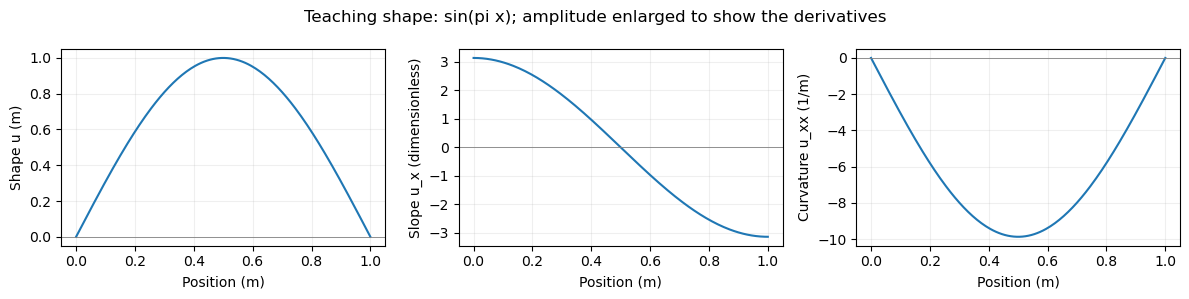

In [6]:
example_x = torch.linspace(0, 1, 201, dtype=torch.float64)
example_shape = torch.sin(math.pi * example_x)
example_slope = math.pi * torch.cos(math.pi * example_x)
example_curvature = -math.pi**2 * torch.sin(math.pi * example_x)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, values, label in zip(axes, (example_shape, example_slope, example_curvature),
                           ("Shape u (m)", "Slope u_x (dimensionless)", "Curvature u_xx (1/m)")):
    ax.plot(example_x, values)
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.set(xlabel="Position (m)", ylabel=label)
    ax.grid(alpha=0.2)
fig.suptitle("Teaching shape: sin(pi x); amplitude enlarged to show the derivatives")
fig.tight_layout()
plt.show()

### Stretching the string: why an integral appears
A displaced segment is slightly longer than its horizontal projection. Pythagoras gives
$$\Delta s=\sqrt{\Delta x^2+\Delta u^2}
=\Delta x\sqrt{1+(\Delta u/\Delta x)^2}.$$
For a small number $q$, $\sqrt{1+q}\approx1+q/2$. For example, $\sqrt{1.01}\approx1.005$.
With $q$ equal to slope squared, the extra length is approximately $\tfrac12 u_x^2\Delta x$.
Add the extra lengths along the whole string:
$$\Delta L\approx\frac12\sum_j (\text{slope}_j)^2\Delta x
\quad\longrightarrow\quad\frac12\int_0^L u_x^2\,dx.$$
The integral is the limit of this accumulation as segments become smaller. $dx$ indicates the little spatial width;
0 and $L$ say where accumulation begins and ends. Squaring prevents positive and negative slopes cancelling.

Combine this extension with $\Delta T=EA\Delta L/L$:
$$\Delta T\approx\frac{EA}{2L}\int_0^L u_x^2\,dx.$$
The Kirchhoff–Carrier model uses this **single extra tension for the whole string**.
Consequently the restoring force depends on displacement itself: this is a nonlinearity.
A larger deflection stretches the string more and can raise its oscillation frequency.

**Energy** helps us derive and check these forces. Kinetic energy is energy of motion, $mv^2/2$;
elastic potential energy is energy stored in deformation. A restoring force points toward lower potential energy:
in one coordinate, $F=-dV/du$. A *variation* is the corresponding calculation for changing an entire shape slightly.
In the deeper derivation below, $\delta u$ means a small trial change of shape, not a time step.
Integration by parts transfers a spatial derivative from that trial change to the shape; endpoint terms vanish
under the stated boundary conditions. This is the integral counterpart of rearranging the product rule
$\frac{d}{dx}(fg)=f'g+fg'$.

In [7]:
# A geometric sum approaching an integral. This sine has analytically known slopes.
example_amplitude = 0.002
for example_intervals in (8, 32, 128):
    example_positions = torch.linspace(0, length, example_intervals + 1, dtype=torch.float64)
    example_heights = example_amplitude * torch.sin(math.pi * example_positions / length)
    example_spacing = length / example_intervals
    example_slopes = torch.diff(example_heights) / example_spacing
    example_extension = 0.5 * torch.sum(example_slopes**2) * example_spacing
    print(f"{example_intervals:3d} segments: extra length ≈ {float(example_extension)*1e6:.5f} micrometres")
# Integral of cos² over one half-cycle is L/2.
print(f"Small-slope integral result: {example_amplitude**2 * math.pi**2 / (4*length)*1e6:.5f} micrometres")

  8 segments: extra length ≈ 9.74342 micrometres
 32 segments: extra length ≈ 9.86168 micrometres
128 segments: extra length ≈ 9.86911 micrometres
Small-slope integral result: 9.86960 micrometres


### Side calculation: where does $I=\pi r^4/4$ come from?

Now that an integral means adding small contributions, return to the circular cross-section.
Divide it into thin rings. A ring at distance $s$ from the centre, of thickness $ds$, has area approximately
circumference × thickness, or $2\pi s\,ds$.
The squared distance from the horizontal bending axis is not $s^2$ everywhere on that ring:
it is $y^2=s^2\sin^2\theta$. Around a full turn, the average of $\sin^2\theta$ is $1/2$
(the average of $\cos^2\theta$ is identical and the two sum to 1).
Therefore the ring contributes $(s^2/2)(2\pi s\,ds)=\pi s^3\,ds$ to the second moment of area.
Add all rings:
$$I=\pi\int_0^r s^3\,ds=\pi\left[\frac{s^4}{4}\right]_0^r=\frac{\pi r^4}{4}.$$
The square brackets mean “value at the upper endpoint minus value at the lower endpoint”.
Integration reverses differentiation: since the derivative of $s^4/4$ is $s^3$, it is the accumulating
function we need. More generally, the derivative of $s^n$ is $n s^{n-1}$ for positive integer $n$.
This explains both the fourth power and the factor $1/4$ in the code.


### Deeper derivation: the energy and complete governing equation

Let $u(x,t)$ be transverse displacement in metres. Write $\mu=\rho A$ for mass per length
(the script's `rA`), and use $\Delta t$ for time step and $\beta$ for wavenumber so neither is confused with stiffness $K$.

| Symbol | Python name | Meaning / units |
|---|---|---|
| $\rho$ | `material_density` | material density, kg/m³ |
| $A=\pi r^2$ | `area` | circular cross-sectional area, m² |
| $\mu=\rho A$ | `linear_mass_density` | mass per length, kg/m |
| $I=\pi r^4/4$ | `moment_of_inertia` | second moment of area, m⁴ |
| $T_0$ | `tension` | resting tension, N |
| $E$ | `young_modulus` | Young's modulus, Pa |
| $c=\sqrt{T_0/\mu}$ | `wave_speed` | wave speed without bending stiffness, m/s |
| $K=\sqrt{EI/\mu}$ | `stiffness` | bending parameter, m²/s; not a spring constant |

Integrating the potential density of Eq. (50) gives
$$V[u]=\frac{T_0}{2}\int_0^L u_x^2\,dx
+\frac{EI}{2}\int_0^L u_{xx}^2\,dx
+\frac{EA}{8L}\left(\int_0^L u_x^2\,dx\right)^2.$$
To see where the nonlinear force comes from, put $S=\int u_x^2dx$.
Its variation is $\delta S=2\int u_x\delta u_xdx=-2\int u_{xx}\delta u\,dx$.
Thus $\delta(EAS^2/(8L))/\delta u=-EA S u_{xx}/(2L)$.
The negative variation of the energy is the force, so the nonlinear term **increases tension**.

Dividing the force law by $\mu$, and adding the damping operator used in MATLAB, gives
$$u_{tt}=c^2u_{xx}-K^2u_{xxxx}
+\frac{E}{2\rho L}\left(\int_0^L u_x^2\,dx\right)u_{xx}
-2\sigma_0u_t+2\sigma_1u_{txx}.$$
Simply supported ends mean $u=u_{xx}=0$ at $0,L$ (paper Eq. 35), not zero slope.
For nonnegative damping coefficients, integration by parts makes both damping contributions dissipative.

Read the final PDE as **acceleration = tension effect + bending effect + stretching effect + two loss effects**.
The two loss coefficients $\sigma_0$ and $\sigma_1$ are explained next.
The notation $u_{txx}$ means one time derivative and two spatial derivatives.
The integral in the nonlinear term produces one number at each instant; it is not a separate force at every point.

## 5. Waves and damping

### Cycles in time and cycles in space
A sine wave repeats. **Frequency** $f$ counts repeats per second (Hz), so one cycle lasts $1/f$ seconds.
Angles measured in radians count a full turn as $2\pi$. Thus **angular frequency** is $\omega=2\pi f$ rad/s:
multiplying it by seconds tells us the phase angle to put into a sine or cosine.

**Wavelength** $\lambda_{\mathrm{wave}}$ is the distance between repeats in space.
**Wavenumber** $\beta=2\pi/\lambda_{\mathrm{wave}}$ counts radians per metre.
For a travelling sinusoid $u(x,t)=a\cos(\beta x-\omega t)$, constant phase travels at speed $\omega/\beta$.
For a string fixed at both ends, standing-wave shapes include $\sin(n\pi x/L)$, where $n=1,2,\ldots$.
A **mode** is one such shape with its own oscillation in time; the first mode has one arch.

Why does squaring frequency appear? Differentiating a sine or cosine twice multiplies it by minus its rate squared:
$u_{tt}=-\omega^2u$, $u_{xx}=-\beta^2u$, and $u_{xxxx}=\beta^4u$.
Substitute into the linear, undamped equation and cancel the common sinusoid:
$-\omega^2=-c^2\beta^2-K^2\beta^4$.
The relation below therefore connects oscillation in time to oscillation in space.
Complex exponentials are just a compact alternative way to perform the same calculation:
$i^2=-1$ and $e^{i\theta}=\cos\theta+i\sin\theta$. Our simulator uses real numbers.

To solve a quadratic $az^2+bz+d=0$, use
$$z=\frac{-b\pm\sqrt{b^2-4ad}}{2a}.$$
The symbol $\pm$ gives two candidates; physical meaning tells us which one is admissible.
Here $z=\beta^2$ cannot be negative. (The letter $a$ in this generic formula is not displacement amplitude.)

### Dispersion: from frequency to squared wavenumber

For a small-amplitude, undamped wave $u\propto e^{i(\beta x-\omega t)}$, the linear PDE gives
$$\omega^2=c^2\beta^2+K^2\beta^4.$$
This is a dispersion relation: bending makes wave speed frequency dependent.
Set $z=\beta^2$; then $K^2z^2+c^2z-\omega^2=0$.
Only the nonnegative root describes a real wavenumber. MATLAB calls the resulting values `param1` and `param2`;
Python calls them `wavenumber_squared_ref_1` and `wavenumber_squared_ref_2` (units m⁻²).
The reference frequencies are converted using $\omega=2\pi f$.

In [8]:
def squared_wavenumber(angular_frequency, wave_speed, stiffness):
    """Positive root of K² z² + c² z - omega² = 0, where z = wavenumber².

    See the explanation above: this uses the undamped, linear dispersion relation.
    """
    dispersion_discriminant = wave_speed**4 + 4 * stiffness**2 * angular_frequency**2
    return (-wave_speed**2 + math.sqrt(dispersion_discriminant)) / (2 * stiffness**2)

In [9]:
damping_ref_freq_1_hz = 0.0
damping_ref_freq_2_hz = 1000.0
t60_ref_1_seconds = 15.0
t60_ref_2_seconds = 10.0

omega_ref_1_rad_s = 2 * math.pi * damping_ref_freq_1_hz
omega_ref_2_rad_s = 2 * math.pi * damping_ref_freq_2_hz
wavenumber_squared_ref_1 = squared_wavenumber(omega_ref_1_rad_s, wave_speed, stiffness)
wavenumber_squared_ref_2 = squared_wavenumber(omega_ref_2_rad_s, wave_speed, stiffness)

In [10]:
for example_omega, example_z in ((omega_ref_1_rad_s, wavenumber_squared_ref_1),
                                (omega_ref_2_rad_s, wavenumber_squared_ref_2)):
    reconstructed_omega_squared = wave_speed**2 * example_z + stiffness**2 * example_z**2
    assert math.isclose(reconstructed_omega_squared, example_omega**2, rel_tol=1e-12, abs_tol=1e-12)
    print(f"omega={example_omega:.6g} rad/s -> beta²={example_z:.6g} 1/m²")

omega=0 rad/s -> beta²=0 1/m²
omega=6283.19 rad/s -> beta²=1607.99 1/m²


### Damping: the size of the vibration shrinks
Friction-like losses remove energy. An **envelope** follows the overall amplitude rather than each oscillation.
Exponential decay $A(t)=A(0)e^{-\alpha t}$ removes the same *fraction* over each equal time interval.
Here $e\approx2.71828$, and $\alpha$ is a decay rate in 1/s. Larger $\alpha$ means faster decay.
An exponential is useful because its derivative is proportional to itself: $d(e^{-\alpha t})/dt=-\alpha e^{-\alpha t}$.
A logarithm reverses exponentiation: $\ln(e^q)=q$; $\log_{10}(10^q)=q$.

Decibels describe ratios. For an amplitude ratio $r$, the level change is $20\log_{10}r$ dB.
A drop of 60 dB means $r=10^{-3}=0.001$: one thousandth of the starting amplitude.
Thus $e^{-\alpha T_{60}}=10^{-3}$, and taking natural logarithms gives
$-\alpha T_{60}=-3\ln10$, or $\alpha=3\ln10/T_{60}$.

The loss model makes decay depend on squared wavenumber: $\alpha=\sigma_0+\sigma_1\beta^2$.
Think of a straight line $y=b+mx$: $\sigma_0$ is its intercept and $\sigma_1$ its slope.
Two specified points determine the line. We subtract their equations to find the slope, then substitute back for the intercept.
Under this model, short spatial waves decay faster when $\sigma_1>0$.

**Source detail:** Bilbao §7.3, printed p. 178, Eq. (7.29) prints the same $6\ln10$ calibration as Russo's script.
We reproduce it, and distinguish it from the conventional amplitude-decay calculation just derived.
The following note is about interpreting that convention, not an undocumented change to the simulator.

### Deeper derivation: the modal decay equation and two-point fit

For a spatial mode, applying $-\partial_{xx}$ multiplies its shape by $z=\beta^2$ (this multiplier is called an eigenvalue). For that mode, the linear damped PDE becomes
$$\ddot a+2(\sigma_0+\sigma_1z)\dot a+(c^2z+K^2z^2)a=0.$$
In the underdamped case its amplitude envelope is $e^{-\alpha t}$ with
$\alpha=\sigma_0+\sigma_1z$. Therefore two specified decay rates give a **straight-line fit**:
$$\sigma_0+\sigma_1z_1=\alpha_1,\qquad
\sigma_0+\sigma_1z_2=\alpha_2.$$
Subtract the equations: $\sigma_1=(\alpha_2-\alpha_1)/(z_2-z_1)$, then substitute back for $\sigma_0$.
The units are $[\sigma_0]=\mathrm{s}^{-1}$ and $[\sigma_1]=\mathrm{m}^2/\mathrm{s}$.
The two squared wavenumbers must differ.

**Reference convention:** a conventional amplitude $T_{60}$ satisfies
$20\log_{10}(e^{-\alpha T_{60}})=-60$, hence $\alpha=3\ln(10)/T_{60}$.
The MATLAB script instead fits $\alpha_i=6\ln(10)/T_i$ while using the factor 2 in the damping operator.
Under the modal approximation above, this halves the actual amplitude $T_{60}$ relative to the labels.
We retain the factor **6** to match its waveform. These are linear calibration targets;
finite-amplitude tension modulation is not included in the calibration.
The 0 Hz target is an extrapolated intercept, not a vibrating mode of this fixed-length string.

Written explicitly, the two solved coefficients are
$$\sigma_1=\frac{\alpha_2-\alpha_1}{z_2-z_1},\qquad
\sigma_0=\alpha_1-\sigma_1z_1.$$
For our first calibration point $z_1=0$, the intercept is simply $\sigma_0=\alpha_1$.


In [11]:
def damping_coefficients(wavenumber_squared_1, wavenumber_squared_2, t60_1, t60_2):
    """Fit sigma_0 + sigma_1*z through the reference's two decay targets.

    Returns sigma_0 [1/s], sigma_1 [m²/s]. The factor 6 matches MATLAB;
    standard amplitude T60 with this damping operator uses 3 (the explanation above).
    """
    reference_decay_rate_1 = 6 * math.log(10) / t60_1
    reference_decay_rate_2 = 6 * math.log(10) / t60_2
    wavenumber_squared_difference = wavenumber_squared_2 - wavenumber_squared_1
    sigma_1 = (reference_decay_rate_2 - reference_decay_rate_1) / wavenumber_squared_difference
    sigma_0 = reference_decay_rate_1 - sigma_1 * wavenumber_squared_1
    return sigma_0, sigma_1

In [12]:
sigma_0, sigma_1 = damping_coefficients(
    wavenumber_squared_ref_1, wavenumber_squared_ref_2,
    t60_ref_1_seconds, t60_ref_2_seconds,
)
sigma_L = sigma_0  # MATLAB alias; not a third independent damping parameter.
print(f"sigma_0={sigma_0:.10g} 1/s; sigma_1={sigma_1:.10g} m²/s")

sigma_0=0.9210340372 1/s; sigma_1=0.0002863929671 m²/s


Reference label 15 s -> conventional linear amplitude T60 7.5 s
Reference label 10 s -> conventional linear amplitude T60 5 s


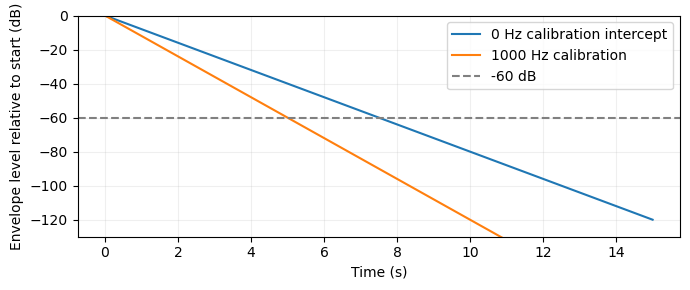

In [13]:
for example_z, example_t60 in ((wavenumber_squared_ref_1, t60_ref_1_seconds),
                              (wavenumber_squared_ref_2, t60_ref_2_seconds)):
    example_rate = sigma_0 + sigma_1 * example_z
    assert math.isclose(example_rate, 6*math.log(10)/example_t60, rel_tol=1e-12)
    print(f"Reference label {example_t60:g} s -> conventional linear amplitude T60 {3*math.log(10)/example_rate:g} s")

example_times = torch.linspace(0, 15, 300, dtype=torch.float64)
fig, ax = plt.subplots(figsize=(7, 3))
for example_z, label in ((wavenumber_squared_ref_1, "0 Hz calibration intercept"),
                         (wavenumber_squared_ref_2, "1000 Hz calibration")):
    example_rate = sigma_0 + sigma_1 * example_z
    ax.plot(example_times, 20*torch.log10(torch.exp(-example_rate*example_times)), label=label)
ax.axhline(-60, color="gray", linestyle="--", label="-60 dB")
ax.set(xlabel="Time (s)", ylabel="Envelope level relative to start (dB)", ylim=(-130, 0))
ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout(); plt.show()

## 6. Replacing a continuous string with a grid

A continuous string has infinitely many locations. We store only $N+1$ points at
$x_j=jh$, where $h=L/N$ and $j=0,1,\ldots,N$. There are **N intervals**, but **N+1 points**.
The two endpoints stay at zero, so we only store the $N-1$ interior displacements.
A superscript $n$ indicates time-step number, not a power: $u_j^n$ is the displacement at point $j$ and time $n\Delta t$.

Take the right slope $(u_{j+1}-u_j)/h$ and subtract the left slope $(u_j-u_{j-1})/h$.
Dividing their difference by $h$ gives a local approximation to curvature:
$$u_{xx}(x_j)\approx\frac{u_{j-1}-2u_j+u_{j+1}}{h^2}.$$
The factor 2 is simply the two occurrences of $u_j$ when we expand the subtraction.
Similarly $u_{tt}\approx(u_j^{n+1}-2u_j^n+u_j^{n-1})/\Delta t^2$.
These are **finite differences**: we use finite intervals in place of infinitesimal ones.

A symbol such as $D^2$ below means “apply the second-difference recipe to every interior point”.
Applying it twice approximates the fourth derivative. At the boundaries, we impose both zero displacement
and zero curvature: **simply supported** ends can rotate; **clamped** ends would additionally fix slope instead.
Supporting reading: Bilbao chapter 5 and §7.2; paper §6.

In [14]:
def second_spatial_derivative(values, grid_spacing):
    """Apply D² with zero endpoint values (the explanation above; paper §6).

    Applying this twice also sets endpoint curvature to zero: simply supported
    bending conditions, not clamped ends.
    """
    derivative = torch.empty_like(values)
    scale = 1 / grid_spacing**2

    derivative[0] = (-2 * values[0] + values[1]) * scale
    derivative[-1] = (values[-2] - 2 * values[-1]) * scale
    derivative[1:-1] = (
        values[:-2] - 2 * values[1:-1] + values[2:]
    ) * scale

    return derivative

Second differences of j² with spacing 1: [2.0, 2.0, 2.0]


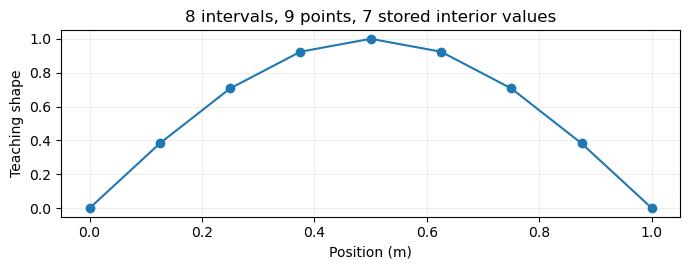

In [15]:
# A tiny vector makes the neighbouring calculation visible.
example_values = torch.tensor([0., 1., 4., 9., 16.], dtype=torch.float64)
example_second_differences = example_values[:-2] - 2*example_values[1:-1] + example_values[2:]
print("Second differences of j² with spacing 1:", example_second_differences.tolist())
assert torch.equal(example_second_differences, torch.full((3,), 2., dtype=torch.float64))
# This local polynomial example does not impose the string's endpoint conditions.

example_N = 8
example_h = length / example_N
example_indices = torch.arange(1, example_N, dtype=torch.float64)
example_mode = torch.sin(math.pi * example_indices / example_N)
example_eigenvalue = -4*math.sin(math.pi/(2*example_N))**2 / example_h**2
torch.testing.assert_close(second_spatial_derivative(example_mode, example_h),
                           example_eigenvalue*example_mode, rtol=1e-12, atol=1e-12)
fig, ax = plt.subplots(figsize=(7, 2.8))
example_nodes = torch.linspace(0, length, example_N + 1)
ax.plot(example_nodes, torch.sin(math.pi*example_nodes/length), "o-")
ax.set(xlabel="Position (m)", ylabel="Teaching shape", title="8 intervals, 9 points, 7 stored interior values")
ax.grid(alpha=0.2); fig.tight_layout(); plt.show()

### Why can we not choose any grid and time step?
A numerical update can amplify its own errors until values grow without bound. This is numerical **instability**;
it is different from the physical string becoming louder because energy was supplied.
A smaller spatial spacing lets us represent finer shapes, but those shapes can oscillate faster.
If the time step does not also shrink enough, the update cannot handle them stably.
Thus a minimum allowed $h$ at fixed $\Delta t$ is not a claim that coarse grids are always more accurate.

The bound below belongs to the reference's linear damped difference scheme. It combines contributions from
wave propagation, bending, and frequency-dependent damping. Set $z=h^2$ to make it a quadratic,
apply the familiar quadratic formula, and take a square root at the end to recover $h$.

For the deeper analysis: a spatial **eigenmode** is a shape a linear operator preserves up to scaling.
Its **eigenvalue** is that scale factor. The sine check above is an example.
A trial error multiplied by $r$ each time step grows when $|r|>1$; “inside the unit disc” means $|r|\le1$,
including when the trial factor is complex. The polynomial below comes from substituting such a trial into the recurrence.

### Deeper derivation: the linear grid bound

For the reference's **linear** update, temporal differences are centred for $u_{tt}$ and $u_t$,
but backward for the $u_{txx}$ loss term. A spatial eigenmode of $-D^2$ with eigenvalue $\lambda\ge0$
has amplification polynomial $A r^2+B r+C=0$, where
$$A=1+\sigma_0\Delta t,$$
$$B=-2+\Delta t^2(c^2\lambda+K^2\lambda^2)+2\sigma_1\Delta t\lambda,$$
$$C=1-\sigma_0\Delta t-2\sigma_1\Delta t\lambda.$$
For nonnegative damping, the quadratic unit-disc conditions $A+B+C\ge0$ and $A-C\ge0$ hold.
The remaining condition $A-B+C\ge0$ requires
$$\Delta t^2(c^2\lambda+K^2\lambda^2)+4\sigma_1\Delta t\lambda\le4.$$
Since the centred difference has $\lambda\le4/h^2$, a sufficient bound is
$$\frac{c^2\Delta t^2+4\sigma_1\Delta t}{h^2}
+\frac{4K^2\Delta t^2}{h^4}\le1.$$
Multiplying by $h^4$ reveals a quadratic in $z=h^2$:
$$z^2-bz-d\ge0,\qquad b=c^2\Delta t^2+4\sigma_1\Delta t,
\qquad d=4K^2\Delta t^2.$$
Thus $h_{\min}=\sqrt{(b+\sqrt{b^2+4d})/2}$.
At $\sigma_1=0$ this reduces to paper Eq. (71).
This is a derivation of the **linear grid bound used in the script**, not a new proof of stability or convergence
for every nonlinear trajectory. The uniform damping coefficient cancels from this bound.

In [16]:
def minimum_grid_spacing(time_step, wave_speed, stiffness, sigma_1):
    """Positive h threshold from h⁴ - (c² dt² + 4 sigma_1 dt) h² - 4 K² dt² = 0.

    the explanation above derives this bound from the linear damped difference scheme.
    The safety margin is applied separately by simulation_grid().
    """
    wave_and_damping_term = wave_speed**2 * time_step**2 + 4 * sigma_1 * time_step
    spacing_discriminant = wave_and_damping_term**2 + 16 * stiffness**2 * time_step**2
    minimum_spacing_squared = (wave_and_damping_term + math.sqrt(spacing_discriminant)) / 2
    return math.sqrt(minimum_spacing_squared)

The safety margin is 1%: multiplying by 1.01 places the grid slightly above the limiting spacing.
Next, the string must contain a whole number of intervals. $\lfloor q\rfloor$ means round down to an integer.
Using $2\lfloor L/(2h)\rfloor$ makes that integer even, so a grid point lands exactly at the midpoint.
After fitting the grid, we solve the same condition for the time step. We do not choose an unrelated new rule.

### Solving back for the time step

The script chooses $h_{\mathrm{initial}}=s h_{\min}$ with $s=1.01$, then
$$N=2\left\lfloor\frac{L}{2h_{\mathrm{initial}}}\right\rfloor,\qquad h=L/N.$$
An even number of intervals puts the midpoint exactly on a grid node. The floor increases spacing.
The script then recalculates $\Delta t$ to use this final grid.
Set $H=h/s$. Requiring $H=h_{\min}(\Delta t)$ gives
$$(c^2H^2+4K^2)\Delta t^2+4\sigma_1H^2\Delta t-H^4=0.$$
Take the positive root. Substituting $H=h/s$ and factoring yields the expression in `stable_time_step` below.
Below, we substitute the computed values back into this quadratic and check its numerical residual.

**Sample-rate convention:** the recurrence retains this $\Delta t$, but MATLAB reports
$f_s=\lfloor1/\Delta t\rfloor$ and takes $\lfloor f_s\,\mathrm{duration}\rfloor$ updates.
It does not reset $\Delta t=1/f_s$. The return value includes the two initial samples, so the output length is
$\lfloor f_s\,\mathrm{duration}\rfloor+2$. We preserve this small time-axis mismatch.

For this quadratic the coefficient of $\Delta t^2$ is $c^2H^2+4K^2$, the coefficient of
$\Delta t$ is $4\sigma_1H^2$, and the constant is $-H^4$. The quadratic formula gives
$$\Delta t=\frac{H^2\left(\sqrt{c^2H^2+4(K^2+\sigma_1^2)}-2\sigma_1\right)}{c^2H^2+4K^2}.$$
We choose the positive time interval. Substituting $H=h/s$ gives the form used in code:
$$\Delta t=\frac{h^2\left(\sqrt{c^2h^2+4s^2(K^2+\sigma_1^2)}-2s\sigma_1\right)}
{s\left(c^2h^2+4K^2s^2\right)},\qquad s=1.01.$$
The intermediate names in the function below refer to the expression under the square root (the radicand)
and the quantity we divide by (the denominator).


In [17]:
def stable_time_step(grid_spacing, wave_speed, stiffness, sigma_1, stability_margin=0.01):
    """Invert h = (1 + margin) * h_min(dt), taking the positive dt root.

    the explanation above gives the quadratic in dt. This factored expression keeps
    the reference's arithmetic order; grid_spacing is in m and the result in s.
    """
    margin_factor = 1 + stability_margin
    time_step_radicand = (
        4 * (stiffness**2 + sigma_1**2) * margin_factor**2
        + wave_speed**2 * grid_spacing**2
    )
    time_step_denominator = margin_factor * (
        4 * stiffness**2 * margin_factor**2 + wave_speed**2 * grid_spacing**2
    )
    return grid_spacing**2 * (
        math.sqrt(time_step_radicand) - 2 * sigma_1 * margin_factor
    ) / time_step_denominator

In [18]:
def simulation_grid(oversampling_factor=oversampling_factor):
    """Return (interval_count, spacing_m, time_step_s, reported_sample_rate_hz).

    The even interval count places a node at L/2. As in MATLAB, the reported
    integer sample rate is floor(1/dt); it does not replace dt (the explanation above).
    """
    stability_margin = 0.01
    requested_time_step = 1 / (oversampling_factor * base_sample_rate)
    initial_grid_spacing = minimum_grid_spacing(
        requested_time_step, wave_speed, stiffness, sigma_1
    ) * (1 + stability_margin)
    grid_interval_count = 2 * math.floor(0.5 * length / initial_grid_spacing)
    if grid_interval_count < 4:
        raise ValueError("The selected grid has too few points for the string update.")
    grid_spacing = length / grid_interval_count
    time_step = stable_time_step(
        grid_spacing, wave_speed, stiffness, sigma_1, stability_margin
    )
    sample_rate = math.floor(1 / time_step)
    return grid_interval_count, grid_spacing, time_step, sample_rate

In [19]:
reference_N, reference_h, reference_dt, reference_rate = simulation_grid()
print(f"N={reference_N}; h={reference_h:.10g} m; dt={reference_dt:.10g} s")
print(f"Reported rate: {reference_rate:,} Hz; actual recurrence rate: {1/reference_dt:.8f} Hz")
assert reference_N % 2 == 0
assert reference_rate == math.floor(1/reference_dt)

# Check the defining condition, not a duplicated square-root expression.
check_H = reference_h / 1.01
check_wave = wave_speed**2 * reference_dt**2 / check_H**2
check_loss = 4 * sigma_1 * reference_dt / check_H**2
check_bending = 4 * stiffness**2 * reference_dt**2 / check_H**4
assert math.isclose(check_wave + check_loss + check_bending, 1., rel_tol=1e-12)
assert math.isclose(minimum_grid_spacing(reference_dt, wave_speed, stiffness, sigma_1), check_H, rel_tol=1e-12)

N=3656; h=0.0002735229759 m; dt=4.433221338e-08 s
Reported rate: 22,556,960 Hz; actual recurrence rate: 22556960.81260114 Hz


## 7. Moving from one state to the next

### Why two starting states?
Acceleration uses three time levels: previous, current, and next.
Rearranging $(u^{n+1}-2u^n+u^{n-1})/\Delta t^2=a^n$ gives
$$u^{n+1}=2u^n-u^{n-1}+\Delta t^2a^n.$$
Without acceleration, this continues the existing velocity. With acceleration, it bends the trajectory.
We need both an initial shape and information about initial velocity. Here the intended initial velocity is zero.
The reference uses the first sine mode, $a\sin(\pi x/L)$, which is zero at both ends and reaches $a$ at the midpoint.

A Taylor expansion predicts a nearby value using local rates of change:
$$u(\Delta t)\approx u(0)+\Delta t\,u_t(0)+\tfrac12\Delta t^2u_{tt}(0).$$
The $1/2$ can be understood by integrating constant acceleration: velocity grows as $at$, and the area under that
velocity ramp is a triangle of area $\tfrac12 a\Delta t^2$.
The deeper explanation preserves an important difference between this standard start and Russo's actual code.

### Initial shape and the reference first step

For interior points $j=1,\ldots,N-1$, use the paper's §6 construction:
$$(D^2\mathbf u)_j=\frac{u_{j-1}-2u_j+u_{j+1}}{h^2},\qquad D^4=D^2D^2.$$
Zero endpoint displacement is supplied in the first application, and zero endpoint curvature in the second.
This is the simply supported condition $u=u_{xx}=0$. The sine initial displacement is
$$u_j^0=a\sin(\pi j/N),\qquad a=2\times10^{-3}\ \mathrm m.$$

A standard zero-velocity Taylor start would be
$$\mathbf u^1=\mathbf u^0+\frac{\Delta t^2}{2}\mathbf a_{\mathrm{PDE}},$$
$$\mathbf a_{\mathrm{PDE}}=c^2D^2\mathbf u^0-K^2D^4\mathbf u^0
+\frac{Eh}{2\rho L}[-(\mathbf u^0)^T D^2\mathbf u^0]D^2\mathbf u^0.$$
Here $\int u_x^2dx\approx-h\mathbf u^T D^2\mathbf u$ explains the nonlinear $h$.
Damping does not contribute to acceleration at an exactly zero initial velocity.

**Reference convention:** MATLAB instead uses $h\mathbf a_{\mathrm{PDE}}$ in this startup expression,
including an additional outer $h$ in the nonlinear term. With point displacement and derivatives already scaled by $h$,
this has an extra length dimension and does not follow the standard Taylor start above.
The notebook reproduces the MATLAB expression exactly for waveform compatibility.
This notebook flags the discrepancy; it does not repair the physical initialization or claim a convergence proof for it.

### Vectors and matrices without mystery
A **vector** is an ordered list: here one displacement for each stored point.
A **dot product** multiplies corresponding entries and adds: $[1,2]\cdot[3,4]=1\times3+2\times4=11$.
In PyTorch this is `torch.dot(a, b)`. A superscript $T$ means transpose: writing a column as a row so that
$\mathbf a^T\mathbf b$ expresses this dot product.

A **matrix** describes a linear recipe mixing vector entries. The second-difference stencil could be stored in a matrix,
but our slicing function applies it without building one. The **identity** matrix $\mathrm{Id}$ leaves a vector unchanged.
An **outer product** $\mathbf q\mathbf q^T$ makes a matrix whose $(i,j)$ entry is $q_iq_j$.
Every column is a multiple of the same vector: it has rank one when $\mathbf q\ne0$.
Crucially, $(\mathbf q\mathbf q^T)\mathbf v=\mathbf q(\mathbf q^T\mathbf v)$:
one dot product and a scalar multiplication replace a whole matrix operation.

The update depends on the next state itself, so we collect all unknown terms on the left.
We then solve a linear system. The special rank-one structure allows an explicit formula, rather than a general matrix inverse.
This is why the code can advance without an iterative nonlinear solver.

In [20]:
example_a = torch.tensor([1., 2.], dtype=torch.float64)
example_b = torch.tensor([3., 4.], dtype=torch.float64)
print("Dot product:", torch.dot(example_a, example_b).item())
print("Outer product:", torch.outer(example_a, example_a))
torch.testing.assert_close(torch.outer(example_a, example_a) @ example_b,
                           example_a * torch.dot(example_a, example_b))

Dot product: 11.0
Outer product: tensor([[1., 2.],
        [2., 4.]], dtype=torch.float64)


### Deeper derivation: collecting and solving the update

Write $\mathbf u=\mathbf u^n$, $\mathbf v=\mathbf u^{n-1}$, and $\mathbf w=\mathbf u^{n+1}$.
The reference time discretisation replaces the nonlinear force by
$$\mathbf f_{\mathrm{nl}}^n=-\frac{EAh}{4L}
(D^2\mathbf u)(D^2\mathbf u)^T(\mathbf w+\mathbf v).$$
As $\mathbf w,\mathbf v\to\mathbf u$, this tends to the spatially discretised nonlinear force in the governing equation above.
This time-centred product corresponds to the non-SAV benchmark in paper Eq. (73), implemented by the MATLAB `else` branch.
Its damped update is
$$\mu\frac{\mathbf w-2\mathbf u+\mathbf v}{\Delta t^2}
=T_0D^2\mathbf u-EID^4\mathbf u+\mathbf f_{\mathrm{nl}}^n
-\mu\sigma_0\frac{\mathbf w-\mathbf v}{\Delta t}
+2\mu\sigma_1D^2\frac{\mathbf u-\mathbf v}{\Delta t}.$$

Multiply by $\Delta t^2$ and collect the known linear terms:
$$\boldsymbol\ell=2\mu\mathbf u
+(T_0\Delta t^2+2\mu\sigma_1\Delta t)D^2\mathbf u
-EI\Delta t^2D^4\mathbf u
+(\mu\sigma_0\Delta t-\mu)\mathbf v
-2\mu\sigma_1\Delta t D^2\mathbf v.$$
Define
$$m=\mu(1+\sigma_0\Delta t),\qquad
\mathbf q=\frac{\Delta t}{2}\sqrt{\frac{hEA}{L}}D^2\mathbf u.$$
The factor $1/2$ in $\mathbf q$ gives the required $1/4$ when forming $\mathbf q\mathbf q^T$.
Moving the unknown part to the left gives
$$(m\mathrm{Id}+\mathbf q\mathbf q^T)\mathbf w
=\underbrace{\boldsymbol\ell-\mathbf q(\mathbf q^T\mathbf v)}_{\mathbf b}.$$

This matrix is a scalar diagonal matrix plus an outer product (rank one).
Sherman–Morrison avoids constructing or inverting a large matrix:
$$\mathbf w=\frac{\mathbf b}{m}
-\frac{\mathbf q}{m}\frac{\mathbf q^T(\mathbf b/m)}{1+\mathbf q^T(\mathbf q/m)}.$$
The denominator is positive when $m>0$. These quantities are now named `mass_scaled_rhs`,
`mass_scaled_direction`, `projected_rhs`, and `correction_denominator` in the code.
Here $m$ has units kg/m: `inverse_mass` means inverse effective mass **per length**.

We can derive this shortcut using only a dot product and algebra. Set $p=\mathbf q^T\mathbf w$.
The system becomes $m\mathbf w+\mathbf q p=\mathbf b$.
Take its dot product with $\mathbf q$:
$$mp+(\mathbf q^T\mathbf q)p=\mathbf q^T\mathbf b
\quad\Rightarrow\quad p=\frac{\mathbf q^T\mathbf b}{m+\mathbf q^T\mathbf q}.$$
Now substitute back: $\mathbf w=(\mathbf b-\mathbf q p)/m$.
Dividing the inner fraction's numerator and denominator by $m$ produces the expression above.
No general-purpose matrix-inverse machinery is needed to understand this special case.


In [21]:
def solve_rank_one(right_hand_side, nonlinear_direction, inverse_mass):
    """Solve (m Id + q qᵀ) u = b by Sherman–Morrison; see the explanation above.

    inverse_mass is 1 / [rho*A*(1 + sigma_0*dt)], not a matrix.
    """
    mass_scaled_rhs = inverse_mass * right_hand_side
    mass_scaled_direction = inverse_mass * nonlinear_direction
    correction_denominator = 1 + torch.dot(nonlinear_direction, mass_scaled_direction)
    projected_rhs = torch.dot(nonlinear_direction, mass_scaled_rhs)
    return mass_scaled_rhs - mass_scaled_direction * (projected_rhs / correction_denominator)

In [22]:
# Compare the shortcut with a direct solve; include zero and nonzero coupling.
example_rhs = torch.tensor([0.2, -0.8, 0.3], dtype=torch.float64)
example_mass = 0.4
for example_direction in ([0., 0., 0.], [1.5, -0.3, 0.7]):
    example_q = torch.tensor(example_direction, dtype=torch.float64)
    example_matrix = example_mass * torch.eye(3, dtype=torch.float64) + torch.outer(example_q, example_q)
    direct_solution = torch.linalg.solve(example_matrix, example_rhs)
    shortcut_solution = solve_rank_one(example_rhs, example_q, 1 / example_mass)
    torch.testing.assert_close(shortcut_solution, direct_solution, rtol=1e-12, atol=1e-14)
print("Rank-one formula agrees with direct matrix solves.")

Rank-one formula agrees with direct matrix solves.


### The complete simulation loop
All ingredients are now defined above. The function below sets up the grid, constructs the two starting states,
then repeatedly computes curvature, builds the right-hand side, solves for the next state, and records its midpoint.

`torch.no_grad()` avoids recording derivatives of the program for automatic differentiation.
Those program derivatives are a separate topic from the spatial and temporal derivatives we have learned here.
This notebook reproduces the reference; it does not yet implement differentiable simulation.

In [23]:
def simulate_string(
    duration_seconds=duration_seconds,
    oversampling_factor=oversampling_factor,
):
    """Return the midpoint displacement samples and their sample rate.

    This follows the explicit, non-SAV update in KCStringSAV_noSplit.m with
    damping enabled. The returned samples are displacements in metres.
    """
    if SAV:
        raise ValueError("This implementation follows the SAV = false branch only.")
    if not damp_on:
        raise ValueError("This configuration is intended to run with damp_on = True.")

    grid_interval_count, grid_spacing, time_step, sample_rate = simulation_grid(
        oversampling_factor
    )
    time_samples = math.floor(sample_rate * duration_seconds)
    spatial_points = grid_interval_count - 1

    # Spatial coordinates are the interior points; both string ends are fixed at zero.
    point_indices = torch.arange(1, grid_interval_count, dtype=torch.float64)
    previous_displacement = amplitude * torch.sin(
        math.pi * point_indices / grid_interval_count
    )

    previous_second_derivative = second_spatial_derivative(
        previous_displacement, grid_spacing
    )
    previous_fourth_derivative = second_spatial_derivative(
        previous_second_derivative, grid_spacing
    )
    nonlinear_initial_term = (
        -torch.dot(previous_displacement, previous_second_derivative)
        * previous_second_derivative
    )

    # Reference initType = 1. Extra h factors are preserved, not a standard
    # Taylor step of the pointwise PDE; see the explanation above for the comparison.
    displacement = previous_displacement + 0.5 * time_step**2 * (
        grid_spacing * wave_speed**2 * previous_second_derivative
        - grid_spacing * stiffness**2 * previous_fourth_derivative
        + grid_spacing
        * (0.5 * young_modulus * grid_spacing / (length * material_density))
        * nonlinear_initial_term
    )

    output_position = (spatial_points + 1) // 2 - 1  # MATLAB's one-based midpoint index.
    output_sound = torch.empty(time_samples + 2, dtype=torch.float64)
    output_sound[0] = previous_displacement[output_position]
    output_sound[1] = displacement[output_position]

    # the explanation above: (m Id + q qᵀ) u_next = linear_term - q (qᵀ u_previous).
    # This is the non-SAV benchmark, related to paper Eq. (73), with damping.
    inverse_mass = 1 / (linear_mass_density + linear_mass_density * sigma_0 * time_step)
    q_scale = time_step * math.sqrt(
        grid_spacing * young_modulus * area / length
    ) * 0.5

    with torch.no_grad():
        for step in range(time_samples):
            displacement_second_derivative = second_spatial_derivative(
                displacement, grid_spacing
            )
            displacement_fourth_derivative = second_spatial_derivative(
                displacement_second_derivative, grid_spacing
            )
            previous_second_derivative = second_spatial_derivative(
                previous_displacement, grid_spacing
            )

            linear_term = (
                2 * linear_mass_density * displacement
                + (tension * time_step**2 + 2 * linear_mass_density * sigma_1 * time_step)
                * displacement_second_derivative
                - young_modulus
                * moment_of_inertia
                * time_step**2
                * displacement_fourth_derivative
                + (linear_mass_density * sigma_0 * time_step - linear_mass_density)
                * previous_displacement
                - 2
                * linear_mass_density
                * sigma_1
                * time_step
                * previous_second_derivative
            )

            q = q_scale * displacement_second_derivative
            previous_projection = torch.dot(q, previous_displacement)
            right_hand_side = linear_term - q * previous_projection
            next_displacement = solve_rank_one(right_hand_side, q, inverse_mass)

            output_sound[step + 2] = next_displacement[output_position]
            previous_displacement = displacement
            displacement = next_displacement

    return output_sound, sample_rate

## 8. Run the notebook's simulator and compare with Russo

First run a short illustration at oversampling 8. It uses the function **defined in this notebook**.
Its lower resolution makes it quick; it is not the reference-resolution validation.
The horizontal axis uses the actual recurrence interval, not the rounded reported sample rate.
The vertical axis is converted from metres to millimetres only for display.

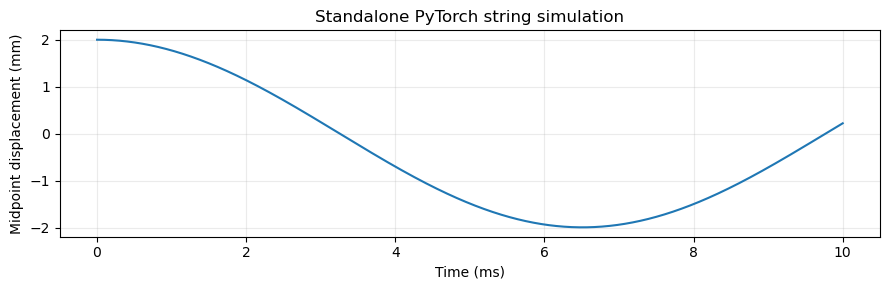

3,518 samples, reported rate 351,695 Hz


In [24]:
demo_duration = 0.01
demo_oversampling = 8
demo_output, demo_rate = simulate_string(demo_duration, demo_oversampling)
_, _, demo_dt, _ = simulation_grid(demo_oversampling)
assert demo_output.numel() == math.floor(demo_rate * demo_duration) + 2
assert torch.isfinite(demo_output).all()
demo_time_ms = torch.arange(demo_output.numel(), dtype=torch.float64) * demo_dt * 1000
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(demo_time_ms, demo_output * 1000)
ax.set(xlabel="Time (ms)", ylabel="Midpoint displacement (mm)", title="Standalone PyTorch string simulation")
ax.grid(alpha=0.25); fig.tight_layout(); plt.show()
print(f"{demo_output.numel():,} samples, reported rate {demo_rate:,} Hz")

### Compatibility check against the actual MATLAB script
The following helper runs a temporary copy of the upstream script with `SAV=false`, `dampOn=true`,
and the requested duration and oversampling. It removes plotting and writes the raw samples to a temporary binary file.
The upstream submodule is not edited. Energy calculations and the update itself are retained.
Octave and the repository's submodule are required for this verification; the simulation above does not depend on them.

We require identical sample rate and length, and compare **every sample**, without normalization, shifting, or resampling.
The tolerance is $10^{-12}+10^{-9}|u_{\mathrm{reference}}|$, accounting for floating-point arithmetic differences.
The short default check uses the reference oversampling 512 and duration 0.0001 s.
A short prefix is not a full-trajectory test. To compare all 0.06 seconds explicitly, call
`compare_with_reference(duration_seconds=0.06)`; this is substantially slower and is not part of routine Run All. The Octave subprocess timeout defaults to 900 seconds; for a longer run, use `compare_with_reference(duration_seconds=0.06, timeout_seconds=3600)`. A timeout means the full comparison is incomplete, not that the waveforms matched or differed.

The plumbing below is a verification tool, not another physical equation you need to learn.

In [25]:
def compare_with_reference(duration_seconds=0.0001, oversampling_factor=512, timeout_seconds=900):
    octave = shutil.which("octave-cli") or shutil.which("octave")
    if octave is None:
        raise RuntimeError("Octave is needed for comparison. Use the Pixi environment; on Windows install Octave on PATH.")
    if project_root is None:
        raise RuntimeError("Run from the repository with its nLinStringsConv-SAV submodule initialized.")

    notebook_output, notebook_rate = simulate_string(duration_seconds, oversampling_factor)
    reference_path = project_root / "nLinStringsConv-SAV" / "KCstring" / "KCStringSAV_noSplit.m"
    reference_text = reference_path.read_text()
    replacements = {
        "SAV = true;": "SAV = false;",
        "dampOn = false;": "dampOn = true;",
        "OSfac = 512;": f"OSfac = {oversampling_factor};",
        "durSec = 0.06;": f"durSec = {duration_seconds};",
    }
    for original, replacement in replacements.items():
        assert original in reference_text, f"Reference changed: missing {original}"
        reference_text = reference_text.replace(original, replacement, 1)
    assert "%%%%% Play & Plot" in reference_text
    reference_text = reference_text.split("%%%%% Play & Plot", 1)[0]

    with tempfile.TemporaryDirectory() as temporary_directory:
        temporary_path = Path(temporary_directory)
        output_path = temporary_path / "reference.bin"
        escaped_output_path = str(output_path).replace("'", "''")
        reference_text += (
            f"\nfid = fopen('{escaped_output_path}', 'wb');\n"
            "fwrite(fid, [SR; Out(:)], 'double');\nfclose(fid);\n"
        )
        script_path = temporary_path / "reference_run.m"
        script_path.write_text(reference_text)
        completed = subprocess.run(
            [octave, "--no-gui", "--quiet", str(script_path)], cwd=temporary_path,
            capture_output=True, text=True, timeout=timeout_seconds,
        )
        if completed.returncode:
            raise RuntimeError(f"Octave failed:\n{completed.stdout}\n{completed.stderr}")
        # Octave and Python run locally: both use the machine's native double format.
        reference_values = torch.frombuffer(bytearray(output_path.read_bytes()), dtype=torch.float64)

    reference_rate = int(reference_values[0].item())
    reference_output = reference_values[1:]
    assert notebook_rate == reference_rate
    assert notebook_output.shape == reference_output.shape
    torch.testing.assert_close(notebook_output, reference_output, rtol=1e-9, atol=1e-12)
    max_error = torch.max(torch.abs(notebook_output - reference_output)).item()
    result = {"samples": notebook_output.numel(), "sample_rate": notebook_rate,
              "duration_seconds": duration_seconds, "max_absolute_error_m": max_error}
    print("Notebook versus Octave:", result)
    return result

In [26]:
short_reference_comparison = compare_with_reference()

Notebook versus Octave: {'samples': 2257, 'sample_rate': 22556960, 'duration_seconds': 0.0001, 'max_absolute_error_m': 2.439142637866709e-13}


### What we have and have not verified
We checked local mathematical identities numerically, compared the rank-one solve with a direct solve,
and compared the notebook's waveform to the reference. Numerical agreement verifies reproduction of that code;
it does not independently establish physical correctness or resolve its documented conventions.

To experiment, edit the parameters where they are introduced, then **restart the kernel and Run All**.
Changed physical parameters will intentionally fail the upstream comparison unless its settings are changed to match;
the supplied reference check targets the default physical parameters. Do not edit the teaching-example variables to configure the simulator.
The current implementation is restricted to positive stiffness, valid positive sample rates and decay times,
distinct calibration wavenumbers, `SAV=False`, and damping enabled.

### Further reading and notation map
- Bilbao (2009), chapters 2 and 5: derivatives, grids, and difference operators; chapter 6: wave motion.
- Bilbao §7.2: stiff strings; §7.3, pp. 177–180: frequency-dependent loss, including Eq. (7.29) on p. 178.
- Bilbao §8.1: Kirchhoff–Carrier stretching and nonlinear string motion.
- Russo, Ducceschi & Bilbao (2026), Eq. (50): energy; §6: spatial discretisation; Eq. (71): undamped grid bound;
  Eq. (73): non-SAV benchmark. The damping terms are taken from the code and the loss model, not presented as part of the paper's undamped equation.

| Notebook | Russo's MATLAB | Meaning |
|---|---|---|
| `linear_mass_density` / $\mu$ | `rA` | mass per length |
| `wave_speed` / $c$ | `c` | flexible-string wave speed |
| `stiffness` / $K$ | `K` | bending parameter |
| `time_step` / $\Delta t$ | `k` | time interval |
| `grid_spacing` / $h$ | `h` | spatial interval |
| squared wavenumbers / $\beta_i^2$ | `param1`, `param2` | spatial calibration values |
| `previous_displacement`, `displacement`, `next_displacement` | `uPrev`, `u`, `uNext` | three successive states |

Bilbao sometimes uses scaled coordinates and different symbols (for example $\gamma$ and $\kappa$).
Translate symbols and units before comparing formulas; the reference code here uses the physical parameters stated above.